# Number concept development

When a child can count to ten, does the child know what "five" means?
Children learn the meaning of the number words one at a time: first
"one", then "two", and so on. The knower-level model of Lee &
Wagenmakers (2013, chapter 19.1) infers how far each child has come from
the Give-N task. This case study takes the PyMC version of the model and
uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the
   answers of the children. `elicito` learns a prior from each expert.
   PyMC then fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.028.
- The translated model draws 10 000 samples about 5 times faster than
  PyMC.
- The elicited quantiles agree with the quantiles of both experts.
- Expert B, who expects a weak effect of the knower level, holds the
  posterior of $\nu$ at the upper bound 8 of the elicited Uniform prior.
  The model then predicts too few correct answers to the small questions.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import io, stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 19], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging
import warnings

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)
# R-hat of a knower level zi that never changes is 0 / 0
warnings.filterwarnings("ignore", message="invalid value encountered in scalar divide")

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The Give-N task

A child sees a bowl of toys and is asked: "Can you give me $q$ toys?". The
child gives $a$ toys, between 1 and 15. The questions ask for 1, 2, 3, 4,
5, 8 or 10 toys. The data are the answers of 20 children, with about 20
questions for each child.

In [4]:
matdata = io.loadmat("data/fc_given.mat")
ns = int(matdata["ns"][0, 0])  # children
nz = int(matdata["nz"][0, 0])  # knower levels
gn = int(matdata["gn"][0, 0])  # possible answers

a_obs = np.int64(matdata["ga"]).flatten() - 1  # answers, from 0
q_obs = np.int64(matdata["gq"]).flatten() - 1  # questions, from 0
valid = np.where(q_obs != -1)[0]  # a child has fewer than 21 questions
nq = matdata["gq"].shape[1]
child = np.repeat(np.arange(ns), nq)[valid]
QUESTIONS = np.unique(q_obs[valid]) + 1

correct_obs = a_obs[valid] == q_obs[valid]

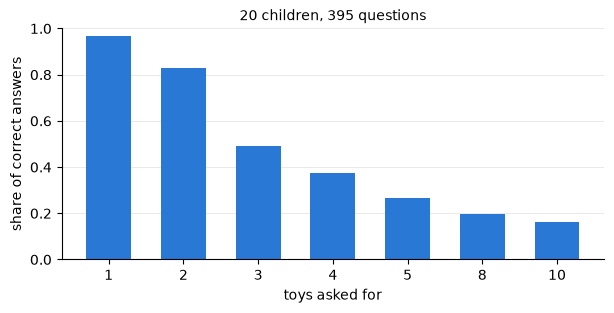

In [5]:
share = [correct_obs[q_obs[valid] == q - 1].mean() for q in QUESTIONS]

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(len(QUESTIONS)), share, color=BLUE, width=0.6)
ax.set(
    xticks=np.arange(len(QUESTIONS)),
    xticklabels=QUESTIONS,
    xlabel="toys asked for",
    ylabel="share of correct answers",
    ylim=(0, 1),
    title=f"{ns} children, {len(valid)} questions",
)
ax.grid(axis="x", visible=False)
plt.show()

Almost all children give 1 toy when they are asked for 1: 57 of 59
answers are correct. The larger the number, the fewer correct answers:
0.83 for 2 toys, 0.49 for 3 toys, and 0.16 for 10 toys.

## The model

Each child $i$ has a latent **knower level** $z_i$ from 0 to 5. A
0-knower knows no number word. A 1-knower knows "one", a 2-knower "one"
and "two", up to the 4-knower. A 5-knower is a CP-knower: the child
knows the counting principle and therefore all number words.

Without knowledge, a child gives $a$ toys with a base rate $\pi_a$. The
knower level changes this base rate by the evidence weight $\nu$:

- A child that knows the number $q$ gives $q$ toys with a weight $\nu$.
- A child that knows a number $a \ne q$ does not give $a$ toys: weight
  $1/\nu$.
- All other answers keep the weight 1.

The weighted base rates, normalized to sum 1, give the probabilities of
the answers. The base rates have a $\operatorname{Dirichlet}(1, \dots, 1)$
prior, the knower levels a uniform Categorical prior, and the book gives
the evidence weight the prior $\nu \sim \operatorname{Uniform}(1, 1000)$.

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node. The base rates and the
knower levels have constant inputs, so the translated model samples them.
$\nu$ is the only prior that `elicito` learns.

In [6]:
def knower_index() -> Any:
    """
    Return the code of each knower level, question and answer

    The code is 0 if the answer keeps the weight 1, 1 if the knower level
    gives it the weight 1 / nu, and 2 if it gives it the weight nu.
    """
    i1 = np.arange(1, nz + 1)[:, None, None]
    j1 = np.arange(1, gn + 1)[None, :, None]
    k1 = np.arange(1, gn + 1)[None, None, :]
    # the knower level is the same as or greater than the answer
    ind1 = (i1 - 1 >= k1).astype(int)
    # the answer matches the question
    ind2 = (k1 == j1).astype(int)
    # 0-knower and CP-knower
    ind3 = (i1 == 1).astype(int)
    ind4 = (i1 == nz).astype(int)
    ind5 = ind3 + ind4 * (2 + ind2) + (1 - ind4) * (1 - ind3) * (ind1 * ind2 + ind1 + 1)
    return ind5 - 1


ind5r = knower_index()

with pm.Model() as model:
    zi = pm.Categorical("zi", p=np.ones(nz) / nz, shape=ns)
    pi = pm.Dirichlet("pi", a=np.ones(gn), shape=gn)
    nu = pm.Uniform(
        "nu", lower=pm.Data("nu_lower", 1.0), upper=pm.Data("nu_upper", 1000.0)
    )
    nu_vec = pm.math.stack([1.0, 1.0 / nu, nu])
    piprime = nu_vec[ind5r] * pi
    npiprime = piprime / pm.math.sum(piprime, axis=-1, keepdims=True)
    pi_ij = npiprime[zi[child], q_obs[valid], :]
    pm.Categorical("aij", p=pi_ij, observed=a_obs[valid])

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `aij`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('nu', 'Uniform')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. We compare the answers `aij`, and the share
of correct answers of the group. For `aij`, the table shows the largest
$D$ of all questions.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw(model["aij"], draws=DRAWS, random_seed=1)

answers = {
    "TensorFlow": np.asarray(tf_out["aij"][0], dtype=float),
    "PyMC": np.asarray(pm_out, dtype=float),
}
samples = {
    "aij": answers,
    "correct": {
        label: (values == q_obs[valid]).mean(axis=-1, keepdims=True)
        for label, values in answers.items()
    },
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<10}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<10}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output       TensorFlow mean, sd     PyMC mean, sd       D
aij                   5.64, 4.42        5.62, 4.42   0.028
correct               0.43, 0.08        0.43, 0.08   0.009


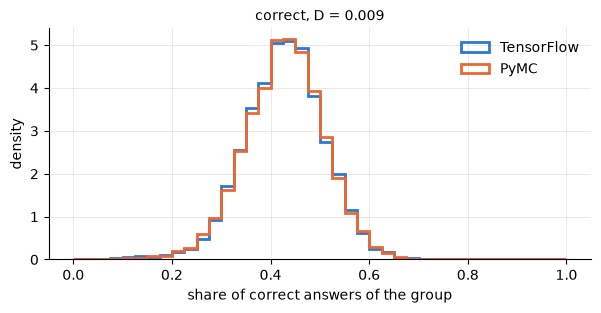

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 1, 41)
for (label, values), color in zip(samples["correct"].items(), (BLUE, ORANGE)):
    ax.hist(
        values[:, 0],
        bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=label,
    )
ax.set(
    xlabel="share of correct answers of the group",
    ylabel="density",
    title=f"correct, D = {distance['correct']:.3f}",
)
ax.legend()
plt.show()

The distributions of the two models overlap. Under the book prior, the
group gives about 43 % correct answers.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model["aij"]], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

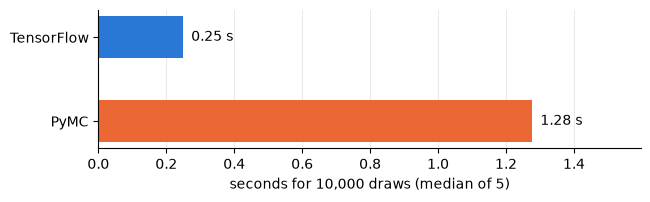

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is about 5 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $\nu$ | Description |
| :-- | :-- | :-- |
| A | Uniform(40, 150) | the knower level decides the answer |
| B | Uniform(2, 8) | the knower level changes the answer a little |

Each expert gives quantiles of two quantities of the group of 20
children:

- **correct, small:** "20 children are asked for 1 or 2 toys. Of 100 such questions,
  how many do they answer correctly?"
- **correct, large:** "The same children are asked for 5, 8 or 10 toys. Of 100 such
  questions, how many are correct?"

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

Most children know "one" and "two", so the share of correct answers to
the small questions shows how strongly the knower level acts. Only
CP-knowers know 5, 8 and 10.

In [12]:
EXPERTS = {
    "Expert A": {"nu": tfd.Uniform(40.0, 150.0)},
    "Expert B": {"nu": tfd.Uniform(2.0, 8.0)},
}
SMALL = np.isin(q_obs[valid] + 1, (1, 2))
LARGE = np.isin(q_obs[valid] + 1, (5, 8, 10))
Q_VALID = tf.constant(q_obs[valid], tf.int32)


def correct_share(questions: Any) -> Any:
    """Return a target function for the share of correct answers"""

    def share(aij: Any) -> Any:
        correct = tf.cast(tf.equal(tf.cast(aij, tf.int32), Q_VALID), tf.float32)
        return tf.reduce_mean(tf.boolean_mask(correct, questions, axis=2), axis=-1)

    return share


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("correct, small", output=correct_share(SMALL), probs=PROBS),
    el.quantiles("correct, large", output=correct_share(LARGE), probs=PROBS),
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=400, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

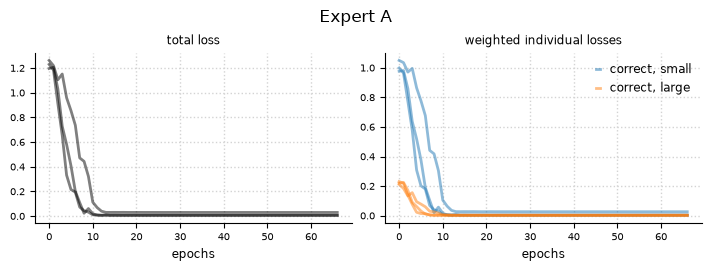

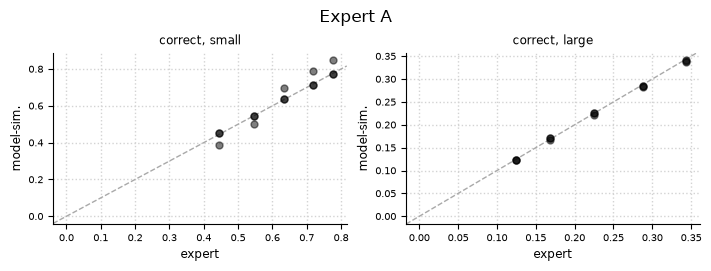

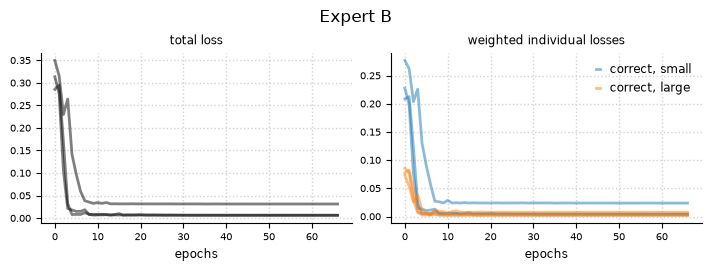

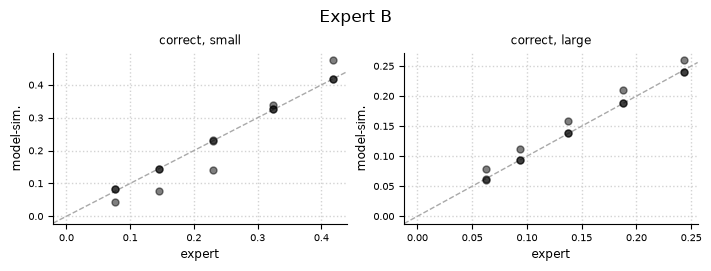

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=2, figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()

A Uniform prior has two bounds. The search can return them in the wrong
order. The samples are then the same, but PyMC needs `lower < upper`. We
therefore sort the bounds. We use the replication with the lowest loss.

In [15]:
def elicited_prior(fit: Any) -> dict[str, float]:
    """Return the bounds of nu of the best replication, sorted"""
    values = fit.hyperparameters()
    lower, upper = sorted((values["nu_lower"], values["nu_upper"]))
    return {"nu_lower": lower, "nu_upper": upper}


PRIORS = {"Book": {"nu_lower": 1.0, "nu_upper": 1000.0}}
PRIORS |= {expert: elicited_prior(fit) for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.2f}" for k, v in prior.items()))

Book      nu_lower 1.00  nu_upper 1000.00
Expert A  nu_lower 62.63  nu_upper 108.56
Expert B  nu_lower 2.06  nu_upper 7.98


## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The book prior,
$\operatorname{Uniform}(1, 1000)$, is the reference. PyMC samples the
knower levels with a Gibbs step and $\nu$ with NUTS.

In [16]:
posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata.posterior
    predictives[label] = idata.posterior_predictive

print(f"{'prior':<10}{'mean of nu':>11}{'90 % interval':>18}")
for label, posterior in posteriors.items():
    values = posterior["nu"].values.ravel()
    low, high = np.quantile(values, [0.05, 0.95])
    print(f"{label:<10}{values.mean():>11.1f}{f'{low:.1f}, {high:.1f}':>18}")

Output()

The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Output()

The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Output()

prior      mean of nu     90 % interval
Book             95.0       40.5, 184.1
Expert A         83.9       65.0, 105.5
Expert B          7.9          7.6, 8.0


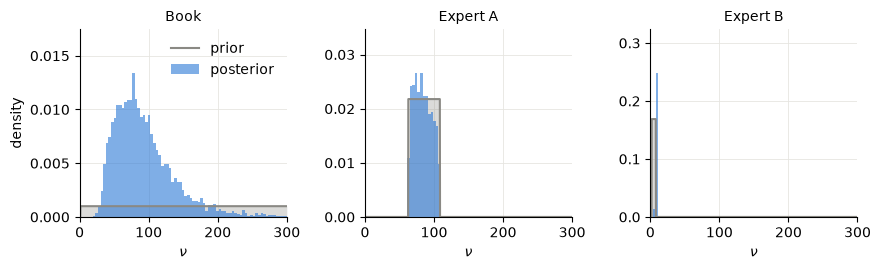

In [17]:
x_grid = np.linspace(0, 300, 1000)

fig, axs = plt.subplots(1, len(PRIORS), figsize=(9, 2.8))
for ax, (label, prior) in zip(axs, PRIORS.items()):
    lower, upper = prior["nu_lower"], prior["nu_upper"]
    density = stats.uniform(lower, upper - lower).pdf(x_grid)
    ax.fill_between(x_grid, density, color=GREY, alpha=0.3, lw=0)
    ax.plot(x_grid, density, color=GREY, lw=1.5, label="prior")
    heights, *_ = ax.hist(
        posteriors[label]["nu"].values.ravel(),
        bins=np.linspace(0, 300, 80),
        density=True,
        histtype="stepfilled",
        color=BLUE,
        alpha=0.6,
        label="posterior",
    )
    ax.set(
        title=label,
        xlabel=r"$\nu$",
        xlim=(0, 300),
        ylim=(0, 1.3 * max(heights.max(), density.max())),
    )
axs[0].set_ylabel("density")
axs[0].legend()
fig.tight_layout()
plt.show()

- **Book prior.** The posterior of $\nu$ has the mean 95 and the 90 %
  interval 41 to 184.
- **Expert A.** The elicited prior is Uniform(62.6, 108.6). The posterior
  has the mean 84 and fills the prior: 65 to 106.
- **Expert B.** The elicited prior is Uniform(2.1, 8.0). The posterior
  stays at the upper bound: mean 7.9, 90 % interval 7.6 to 8.0. The data
  want a larger $\nu$, but the Uniform prior does not allow it.

PyMC warns that the effective sample size is below 100 per chain for
some parameters. The knower levels are discrete, and PyMC samples them
with a Gibbs step.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots are the observed shares of correct answers. The bars and lines
are the median and the 90 % interval of the simulated shares.

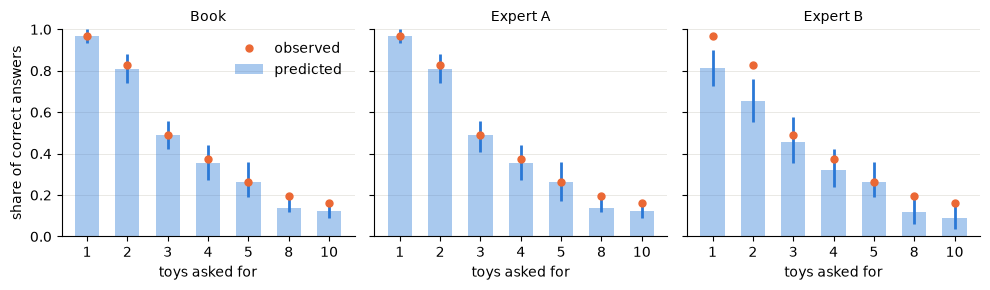

In [18]:
x_q = np.arange(len(QUESTIONS))

fig, axs = plt.subplots(1, len(PRIORS), figsize=(10, 3), sharey=True)
for ax, (label, predictive) in zip(axs, predictives.items()):
    correct_rep = predictive["aij"].values.reshape(-1, len(valid)) == q_obs[valid]
    shares = np.stack(
        [correct_rep[:, q_obs[valid] == q - 1].mean(axis=1) for q in QUESTIONS], axis=1
    )
    low, mid, high = np.quantile(shares, [0.05, 0.5, 0.95], axis=0)
    ax.bar(x_q, mid, color=BLUE, alpha=0.4, width=0.6, label="predicted")
    ax.vlines(x_q, low, high, color=BLUE, lw=2)
    ax.plot(x_q, share, "o", color=ORANGE, ms=5, label="observed")
    ax.set(
        title=label,
        xticks=x_q,
        xticklabels=QUESTIONS,
        xlabel="toys asked for",
        ylim=(0, 1),
    )
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("share of correct answers")
axs[0].legend()
fig.tight_layout()
plt.show()

With the book prior and with expert A, the observed shares are inside or
at the edge of the 90 % intervals. With expert B, the model predicts too
few correct answers to the small questions: for 1 toy, a median of about
0.81 against 0.97 observed, and for 2 toys about 0.65 against 0.83.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance is 0.028.
- **Speed.** The translated model is about 5 times faster than PyMC.
- **One parameter.** Two quantities of the group are enough to elicit
  the one prior with `pm.Data` inputs.
- **Uniform priors.** A narrow Uniform prior is a strong statement. The
  posterior predictive check shows the misfit when the data want a value
  outside the bounds.

## Appendix

The PyMC3 model comes from the notebook
[NumberConceptDevelopment.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/NumberConceptDevelopment.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [19]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Sarnecka, B. W. (2010). A model of knower-level behavior in
  number concept development. *Cognitive Science*, 34, 51-67.
- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.